# Brazo horizontal 2R para ordenar envases sobre una mesa

Traslado por deslizamiento: el envase permanece apoyado en z=0.

## Geometría y supuestos
- L1=150 mm: se interpreta como distancia entre ejes; confirmar porque el dibujo no identifica los centros.
- L2=130 mm: desde eje del codo hasta montaje de garra.
- Garra: 100 mm desde montaje a puntas. TCP a 70 mm del montaje **supuesto ajustable**, no medido. Por tanto longitud efectiva codo-TCP=200 mm y alcance ideal 50..350 mm.
- Soporte 60 mm y primer eslabón de espesor 20 mm: marco de referencia elegido a 70 mm sobre la mesa.
- H_TCP=40 mm **supuesto**: la cota de 40 mm del dibujo parece corresponder al borde inferior, no al centro de agarre. Ajustar tras medir la garra. El desplazamiento relativo entre marcos se calcula, no se impone como -40 mm.
- Diámetro de envase 30 mm, altura 65 mm y masa 80 g **supuestos**. Medir el envase Apu/Acrilex real; el volumen 37/50 ml no determina estos valores.



L efectiva codo->TCP: 200 mm; alcance ideal 50..350 mm
Plano 1: 70 mm; TCP: 40 mm; H relativo: -30 mm
DH: (q1, d1=0, a1=L1, alpha1=0); (q2, d2=H_REL, a2=L2, alpha2=0)
Herramienta fija: Tx(G_TCP); altura de base respecto a mesa: H_PLANO1.
Inicio  : x=  200.0 y=    0.0 mm; q=[-67.98 112.02] grados
Agarre  : x=  220.0 y=  100.0 mm; q=[-31.21  93.92] grados
Destino : x=  100.0 y= -170.0 mm; q=[-128.33  113.16] grados
Duración: 5.90 s; 296 muestras sin tiempos duplicados.
Rangos articulares [grados]: [[-150.35  -31.21]
 [  93.92  133.58]]
Máximas velocidades [grados/s]: [204.36  74.69]
Verificación matemática DH/fórmula: 6.21e-17 m
Verificación matemática FK(IK): 8.89e-17 m
Cuantización IDEAL encoder: 0.472 mm; paso=0.150 grados
No son errores experimentales. No se modelan fricción, fuerza de agarre ni control de motores.


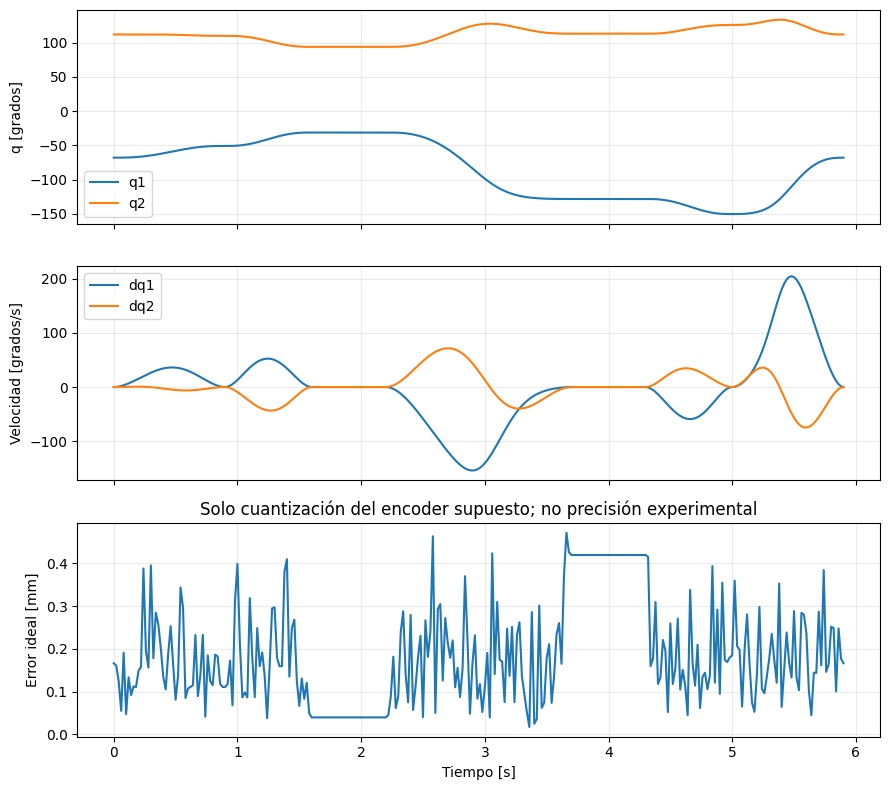

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

L1 = 0.150
L2 = 0.130
G_TOTAL = 0.100
G_TCP = 0.070
G_CUERPO = 0.045
H_SOPORTE = 0.060
ESPESOR_L1 = 0.020
H_PLANO1 = H_SOPORTE + ESPESOR_L1 / 2
H_TCP = 0.040
H_REL = H_TCP - H_PLANO1

D_ENVASE = 0.030
H_ENVASE = 0.065
MASA_ENVASE = 0.080
APERTURA_TOTAL = 0.050
CPR = 2400
CODO = +1
LIMITES_Q = np.radians([[-180, 180], [5, 175]])
DT = 0.020
T_CIERRE = 0.6
T_APERTURA = 0.6
RETIRADA = 0.050
HOME = np.array([0.20, 0.00])
PICK = np.array([0.22, 0.10])
PLACE = np.array([0.10, -0.17])
MOSTRAR_ANIMACION = True
GUARDAR_GIF = False

LE = L2 + G_TCP
R_MIN, R_MAX = abs(L1 - LE), L1 + LE
R_ENVASE = D_ENVASE / 2
SEMI_ABIERTA = APERTURA_TOTAL / 2
SEMI_CERRADA = R_ENVASE


def validar_parametros():
    if min(L1, L2, G_TOTAL, D_ENVASE, H_ENVASE, CPR, DT) <= 0:
        raise ValueError('Las dimensiones, CPR y DT deben ser positivas.')
    if not (0 < G_CUERPO < G_TCP < G_TOTAL):
        raise ValueError('Se requiere 0 < G_CUERPO < G_TCP < G_TOTAL.')
    if G_TCP - R_ENVASE <= G_CUERPO or G_TCP + R_ENVASE >= G_TOTAL:
        raise ValueError('Los dedos no abarcan el diámetro del envase con estas medidas.')
    if APERTURA_TOTAL <= D_ENVASE:
        raise ValueError('La apertura debe superar el diámetro del envase.')
    if not 0 < H_TCP < H_ENVASE:
        raise ValueError('El centro de agarre debe estar dentro de la altura del envase.')
    if CODO not in (-1, +1):
        raise ValueError('CODO debe ser +1 o -1.')


def dh(theta, d, a):
    """DH estándar con alpha=0: Rz(theta) Tz(d) Tx(a)."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0., a*c], [s, c, 0., a*s],
                     [0., 0., 1., d], [0., 0., 0., 1.]])


def fk(q):
    """Devuelve TCP respecto a MESA y puntos base/codo/montaje/TCP.
    DH: A1(q1,0,L1), A2(q2,H_REL,L2); herramienta fija Tx(G_TCP).
    El marco de mesa está en z=0; el marco {0} está en z=H_PLANO1.
    """
    Tm0 = np.eye(4)
    Tm0[2, 3] = H_PLANO1
    Tm1 = Tm0 @ dh(q[0], 0., L1)
    Tm2 = Tm1 @ dh(q[1], H_REL, L2)
    T2tcp = np.eye(4)
    T2tcp[0, 3] = G_TCP
    Tmtcp = Tm2 @ T2tcp
    codo_bajo = Tm1[:3, 3].copy()
    codo_bajo[2] = H_TCP
    puntos = np.vstack([Tm0[:3, 3], Tm1[:3, 3], codo_bajo,
                        Tm2[:3, 3], Tmtcp[:3, 3]])
    return Tmtcp, puntos


def fk_cerrada(q):
    q1, q2 = q
    return np.array([L1*np.cos(q1) + LE*np.cos(q1+q2),
                     L1*np.sin(q1) + LE*np.sin(q1+q2), H_TCP])


def ik(p):
    p = np.asarray(p, dtype=float)
    if p.shape not in ((2,), (3,)) or not np.isfinite(p).all():
        raise ValueError('Posición inválida: usar [x,y] o [x,y,z].')
    if p.size == 3 and not np.isclose(p[2], H_TCP, atol=1e-9, rtol=0):
        raise ValueError('El brazo solo alcanza la altura fija H_TCP.')
    x, y = p[:2]
    D = (x*x + y*y - L1*L1 - LE*LE) / (2*L1*LE)
    if abs(D) > 1 + 1e-10:
        raise ValueError(f'Punto ({x:.3f},{y:.3f}) fuera del alcance.')
    D = np.clip(D, -1., 1.)
    q2 = np.arctan2(CODO*np.sqrt(max(0., 1-D*D)), D)
    q1 = np.arctan2(y, x) - np.arctan2(LE*np.sin(q2), L1+LE*np.cos(q2))
    return np.array([q1, q2])


def jacobiano(q):
    a, b = q[0], q.sum()
    return np.array([[-L1*np.sin(a)-LE*np.sin(b), -LE*np.sin(b)],
                     [ L1*np.cos(a)+LE*np.cos(b),  LE*np.cos(b)]])


def direccion(p):
    phi = ik(p).sum()
    return np.array([np.cos(phi), np.sin(phi)])


def crear_trayectoria():
    pre = PICK - RETIRADA*direccion(PICK)
    post = PLACE - RETIRADA*direccion(PLACE)

    bloques = [
        (HOME, pre, .9, SEMI_ABIERTA, SEMI_ABIERTA, 0, 'Aproximación'),
        (pre, PICK, .7, SEMI_ABIERTA, SEMI_ABIERTA, 0, 'Entrada al envase'),
        (PICK, PICK, T_CIERRE, SEMI_ABIERTA, SEMI_CERRADA, 0, 'Cierre'),
        (PICK, PLACE, 1.5, SEMI_CERRADA, SEMI_CERRADA, 1, 'Deslizamiento'),
        (PLACE, PLACE, T_APERTURA, SEMI_CERRADA, SEMI_ABIERTA, 2, 'Apertura'),
        (PLACE, post, .7, SEMI_ABIERTA, SEMI_ABIERTA, 2, 'Retirada'),
        (post, HOME, .9, SEMI_ABIERTA, SEMI_ABIERTA, 2, 'Regreso')]
    tiempo, pos, vel, ancho, estado, fases = [], [], [], [], [], []
    t0 = 0.
    for k, (a,b,T,w0,w1,m,nombre) in enumerate(bloques):
        pasos = max(2, int(np.ceil(T/DT)))
        tau = np.linspace(0., 1., pasos+1)
        s = 10*tau**3 - 15*tau**4 + 6*tau**5
        sd = (30*tau**2 - 60*tau**3 + 30*tau**4)/T
        sel = slice(None) if k == 0 else slice(1, None)
        tiempo.extend((t0+tau*T)[sel])
        pos.extend((a+s[:,None]*(b-a))[sel])
        vel.extend((sd[:,None]*(b-a))[sel])
        ancho.extend((w0+s*(w1-w0))[sel])
        estado.extend(np.full(pasos+1, m)[sel])
        fases.extend(np.full(pasos+1, nombre)[sel])
        t0 += T
    return (np.array(tiempo), np.array(pos), np.array(vel),
            np.array(ancho), np.array(estado), np.array(fases))


def simular():
    validar_parametros()
    t, Xd, Vd, ancho, estado, fases = crear_trayectoria()
    Q = np.unwrap(np.array([ik(p) for p in Xd]), axis=0)
    if np.any(Q < LIMITES_Q[:,0]-1e-10) or np.any(Q > LIMITES_Q[:,1]+1e-10):
        raise ValueError('Trayectoria fuera de LIMITES_Q; revisar estaciones o rama del codo.')
    det = L1*LE*np.sin(Q[:,1])
    if np.min(np.abs(det)) < 1e-6:
        raise ValueError('Trayectoria demasiado cerca de una singularidad.')
    Qd = np.array([np.linalg.solve(jacobiano(q), v) for q,v in zip(Q,Vd)])
    Pdh = np.array([fk(q)[0][:3,3] for q in Q])
    Pcf = np.array([fk_cerrada(q) for q in Q])
    error_fk = np.linalg.norm(Pdh-Pcf, axis=1)
    error_ik = np.linalg.norm(Pdh[:,:2]-Xd, axis=1)
    paso_encoder = 2*np.pi/CPR
    Qenc = np.round(Q/paso_encoder)*paso_encoder
    Penc = np.array([fk_cerrada(q) for q in Qenc])
    error_enc = 1000*np.linalg.norm(Penc-Pcf, axis=1)
    envase = np.where(estado[:,None] == 0, PICK,
                     np.where(estado[:,None] == 1, Pdh[:,:2], PLACE))
    print(f'L efectiva codo->TCP: {LE*1000:.0f} mm; alcance ideal {R_MIN*1000:.0f}..{R_MAX*1000:.0f} mm')
    print(f'Plano 1: {H_PLANO1*1000:.0f} mm; TCP: {H_TCP*1000:.0f} mm; H relativo: {H_REL*1000:.0f} mm')
    print('DH: (q1, d1=0, a1=L1, alpha1=0); (q2, d2=H_REL, a2=L2, alpha2=0)')
    print('Herramienta fija: Tx(G_TCP); altura de base respecto a mesa: H_PLANO1.')
    for nombre,p in [('Inicio',HOME),('Agarre',PICK),('Destino',PLACE)]:
        q = ik(p)
        print(f'{nombre:8s}: x={p[0]*1000:7.1f} y={p[1]*1000:7.1f} mm; q={np.degrees(q).round(2)} grados')
    print(f'Duración: {t[-1]:.2f} s; {len(t)} muestras sin tiempos duplicados.')
    print('Rangos articulares [grados]:', np.degrees(np.column_stack((Q.min(0),Q.max(0)))).round(2))
    print('Máximas velocidades [grados/s]:', np.degrees(np.abs(Qd).max(0)).round(2))
    print(f'Verificación matemática DH/fórmula: {error_fk.max():.2e} m')
    print(f'Verificación matemática FK(IK): {error_ik.max():.2e} m')
    print(f'Cuantización IDEAL encoder: {error_enc.max():.3f} mm; paso={360/CPR:.3f} grados')
    print('No son errores experimentales. No se modelan fricción, fuerza de agarre ni control de motores.')

    fig, (ax, lateral) = plt.subplots(1,2,figsize=(12,5.8), gridspec_kw={'width_ratios':[1.2,1]})
    margen = R_MAX + G_TOTAL-G_TCP + .06
    ax.set(xlim=(-margen,margen), ylim=(-margen,margen), xlabel='x [m]', ylabel='y [m]',
           title='Vista superior: traslado sobre mesa')
    ax.set_aspect('equal'); ax.grid(alpha=.25)
    th = np.linspace(0,2*np.pi,300)
    for r in (R_MIN,R_MAX):
        ax.plot(r*np.cos(th),r*np.sin(th),'--',color='0.65',lw=.8)
    ax.plot(Xd[:,0],Xd[:,1],':',color='0.7',label='Trayectoria programada')
    ax.plot(*PICK,'gx',ms=9,label='Origen'); ax.plot(*PLACE,'bs',mfc='none',label='Destino')
    brazo, = ax.plot([],[],'o-',lw=4,label='Eslabones')
    cuerpo, = ax.plot([],[],'-',color='0.3',lw=9)
    palma, = ax.plot([],[],'k-',lw=2)
    dedo1, = ax.plot([],[],'k-',lw=3); dedo2, = ax.plot([],[],'k-',lw=3)
    tcp_art, = ax.plot([],[],'r+',ms=9,label='TCP')
    rastro, = ax.plot([],[],'r-',lw=1)
    vaso = plt.Circle(PICK,R_ENVASE,facecolor='tab:orange',edgecolor='k',zorder=5)
    ax.add_patch(vaso); ax.legend(loc='upper left',fontsize=8)
    texto = ax.text(.02,.02,'',transform=ax.transAxes,fontsize=9)
    lateral.set(xlim=(-margen,margen),ylim=(-.005,max(H_PLANO1,H_ENVASE)+.055),
                xlabel='x [m]',ylabel='z sobre mesa [m]',title='Proyección lateral x-z')
    lateral.grid(alpha=.25); lateral.axhline(0,color='saddlebrown',lw=3,label='Mesa')
    lateral.axhline(H_TCP,color='r',ls=':',lw=1,label='Altura fija TCP')
    lateral.plot([0,0],[0,H_SOPORTE],color='0.45',lw=12,label='Soporte')
    linea_z, = lateral.plot([],[],'o-',lw=3)
    vaso_z = plt.Rectangle((PICK[0]-R_ENVASE,0),D_ENVASE,H_ENVASE,
                            facecolor='tab:orange',edgecolor='k',alpha=.65)
    lateral.add_patch(vaso_z); lateral.legend(fontsize=8)

    def dibujar(k):
        T,p = fk(Q[k]); phi = Q[k].sum()
        u = np.array([np.cos(phi),np.sin(phi)]); normal = np.array([-u[1],u[0]])
        montaje = p[3,:2]; fondo = montaje+G_CUERPO*u
        punta = montaje+G_TOTAL*u
        brazo.set_data(p[:4,0],p[:4,1])
        cuerpo.set_data([montaje[0],fondo[0]],[montaje[1],fondo[1]])
        extremos = np.vstack((fondo+ancho[k]*normal,fondo-ancho[k]*normal))
        palma.set_data(extremos[:,0],extremos[:,1])
        for artista,signo in [(dedo1,+1),(dedo2,-1)]:
            pts = np.vstack((fondo+signo*ancho[k]*normal,punta+signo*ancho[k]*normal))
            artista.set_data(pts[:,0],pts[:,1])
        tcp_art.set_data([T[0,3]],[T[1,3]])
        rastro.set_data(Pdh[:k+1,0],Pdh[:k+1,1]); vaso.center=envase[k]
        linea_z.set_data(p[:,0],p[:,2]); vaso_z.set_x(envase[k,0]-R_ENVASE)
        texto.set_text(f't = {t[k]:.2f} s | {fases[k]}\nEnvase apoyado en la mesa; z_TCP = {H_TCP*1000:.0f} mm')
        return brazo,cuerpo,palma,dedo1,dedo2,tcp_art,rastro,vaso,linea_z,vaso_z,texto

    dibujar(0); fig.tight_layout()
    frames = np.unique(np.r_[np.arange(0,len(t),3),len(t)-1])
    anim = FuncAnimation(fig,dibujar,frames=frames,interval=DT*3000,blit=False,repeat=False)
    if GUARDAR_GIF:
        from matplotlib.animation import PillowWriter
        anim.save('brazo_2R_mesa.gif',writer=PillowWriter(fps=1/(3*DT)))
    if MOSTRAR_ANIMACION:
        try:
            from IPython.display import HTML, display
            from IPython import get_ipython
            if get_ipython() is not None:
                plt.close(fig); plt.rcParams['animation.embed_limit']=60
                display(HTML(anim.to_jshtml()))
            else:
                plt.show()
        except ImportError:
            plt.show()

    fig2, axs = plt.subplots(3,1,figsize=(9,8),sharex=True)
    axs[0].plot(t,np.degrees(Q)); axs[0].set_ylabel('q [grados]'); axs[0].legend(['q1','q2'])
    axs[1].plot(t,np.degrees(Qd)); axs[1].set_ylabel('Velocidad [grados/s]'); axs[1].legend(['dq1','dq2'])
    axs[2].plot(t,error_enc); axs[2].set_ylabel('Error ideal [mm]'); axs[2].set_xlabel('Tiempo [s]')
    axs[2].set_title('Solo cuantización del encoder supuesto; no precisión experimental')
    for a in axs: a.grid(alpha=.25)
    fig2.tight_layout()
    if MOSTRAR_ANIMACION: plt.show()
    return {'t':t,'Xd':Xd,'Q':Q,'Qd':Qd,'TCP':Pdh,'envase':envase,
            'error_fk':error_fk,'error_ik':error_ik,'error_encoder_mm':error_enc,
            'animacion':anim,'figura':fig,'graficas':fig2}


if __name__ == '__main__':
    resultados = simular()
